In [2]:
# Import the library to mount Google Drive
from google.colab import drive
# Mount the Google Drive at /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


Confusion Matrix

In [5]:
file_name = "run-w9auyal5-conf_mat_top5_table.json"
file_path = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Models/{file_name}"

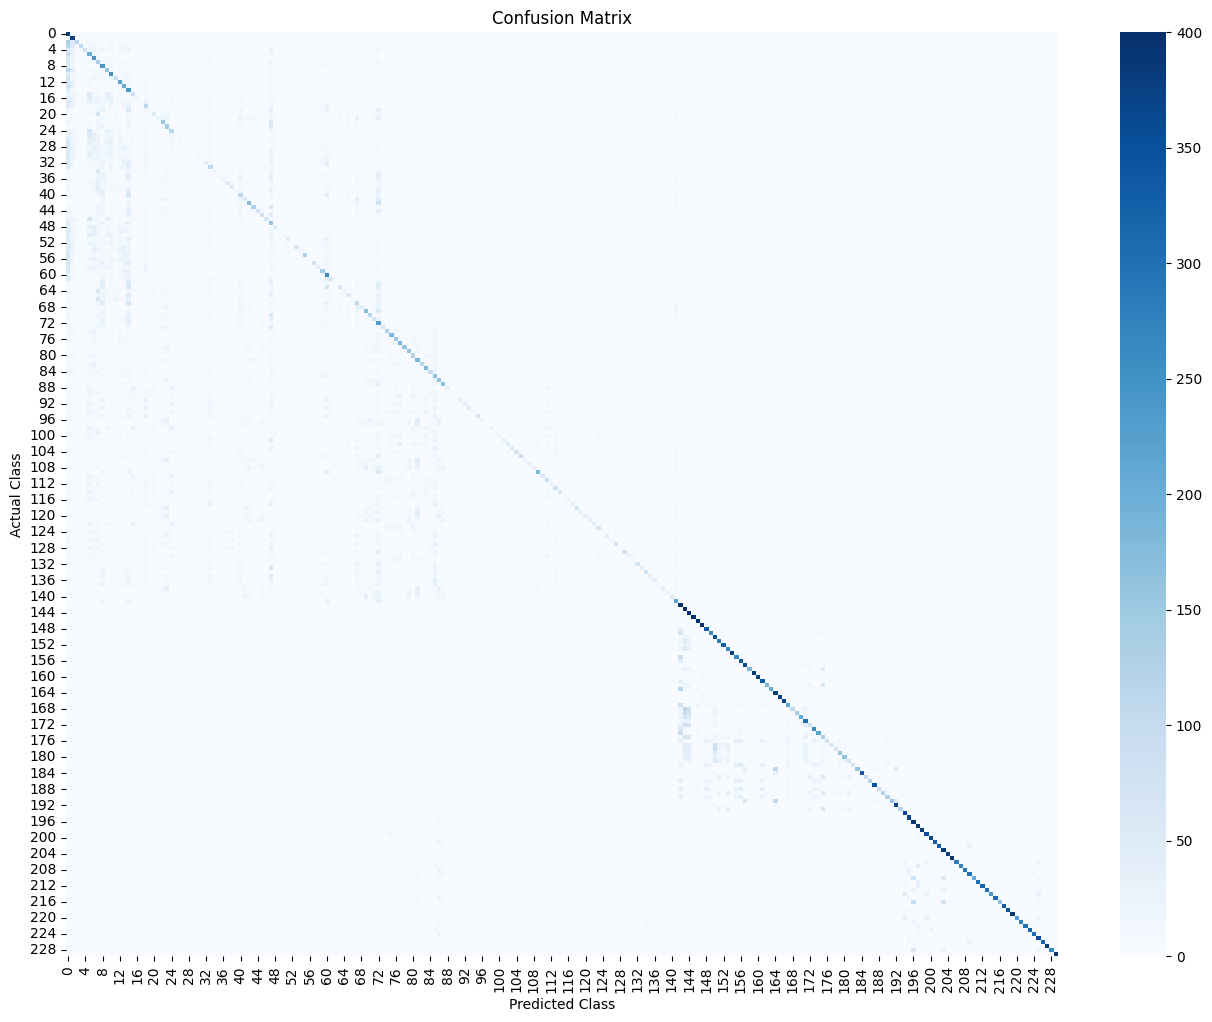

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import json

# Load JSON file
with open(file_path, "r") as f:
    data = json.load(f)

# Convert to DataFrame
df = pd.DataFrame(data["data"], columns=data["columns"])

# Parse "nPredictions" column as list of ints
#df["nPredictions"] = df["nPredictions"].apply(eval)  # if stored as strings like '[4,7,10,5,1]'
num_classes = 230  # adjust as needed
conf_matrix = np.zeros((num_classes, num_classes), dtype=float)
for _, row in df.iterrows():
    actual = int(row["Actual"])
    predicted = int(row["Predicted"])
    weight = float(row["nPredictions"])
    conf_matrix[actual, predicted] += weight
plt.figure(figsize=(16, 12))
sns.heatmap(conf_matrix, cmap="Blues", annot=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.savefig("confusion_matrix.png")
plt.show()
